# Notebook Dedicated to observe the PMT Charge Distribution (QHL and QHS) using the candidate events and Compare with MC Expectations

In [1]:
import numpy as np
import scipy.stats as stats

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.font_manager as fm
import seaborn as sn

## Log-likelihood Fit

In [27]:
def calc_poisson_likelihood_chi2(mc_count, data_count):
    
    """
    Compute the -2 ln(Lambda) of Baker-Cousins.
    
    Parameters:
    - mc_count: predicted model counts
    - data_count: observed real data couns

    Return:
    - total chi^2 naker-Cousin Likelihood
    - chi^2 value for each bin
    - pull/oscilaltions between model and data observation according to the likelihood formula
    """
    
    O = np.asarray(data_count, dtype=float)  # Observed
    E = np.asarray(mc_count, dtype=float)    # Expected
    
    # 3. Inicializar el término del logaritmo en ceros
    log_term = np.zeros_like(O)
    
    # Avoid zero counting
    O_mask_non_0 = (O > 0)
    E_mask_non_0 = (E > 0)
    log_term[O_mask_non_0] = O[O_mask_non_0] * np.log(O[O_mask_non_0] / E[E_mask_non_0])
    
    # Likelihood for each bin
    chi2_lambda_terms = 2 * (E[E_mask_non_0] - O[O_mask_non_0] + log_term[O_mask_non_0])
    
    # Total Likelohood/fit value
    chi2_lambda_total = np.sum(chi2_lambda_terms)

    # Pull values between model and data: How MC and Data model diference oscillate
    pull = (np.sign(O[O_mask_non_0]-E[E_mask_non_0]))*np.sqrt(chi2_lambda_terms)

    return chi2_lambda_total, chi2_lambda_terms, pull

In [2]:
def calc_poisson_likelihood_chi2(mc_count, data_count):
    """
    Compute the -2 ln(Lambda) of Baker-Cousins handling zeros safely 
    while preserving array shapes (bin-by-bin).
    
    Parameters:
    - mc_count: predicted model counts (E)
    - data_count: observed real data counts (O)

    Return:
    - chi2_lambda_total: total chi^2 Baker-Cousin Likelihood
    - chi2_lambda_terms: chi^2 value for each bin (same shape as input)
    - pull: pulls between model and data observation (same shape as input)
    """
    O = np.asarray(data_count, dtype=float)  # Observed
    E = np.asarray(mc_count, dtype=float)    # Expected
    
    # Inicializar el array de resultados con las mismas dimensiones que O y E
    chi2_lambda_terms = np.zeros_like(O)
    
    # Caso 1: Ambos son mayores que 0 (Fórmula estándar de Baker-Cousins)
    mask_both_pos = (O > 0) & (E > 0)
    chi2_lambda_terms[mask_both_pos] = 2 * (
        E[mask_both_pos] - O[mask_both_pos] + 
        O[mask_both_pos] * np.log(O[mask_both_pos] / E[mask_both_pos])
    )
    
    # Caso 2: Observación es 0, pero la expectativa es > 0 (O = 0, E > 0)
    # El término O * log(O/E) es 0, por lo que queda 2 * (E - 0 + 0) = 2 * E
    mask_O0_Epos = (O == 0) & (E > 0)
    chi2_lambda_terms[mask_O0_Epos] = 2 * E[mask_O0_Epos]
    
    # Caso 3: Ambos son 0 (O = 0, E = 0) -> Contribución 0 (ya está en ceros)
    
    # Caso 4: Observación > 0, pero expectativa es 0 (O > 0, E = 0)
    # Penalización infinita
    mask_Opos_E0 = (O > 0) & (E == 0)
    chi2_lambda_terms[mask_Opos_E0] = np.inf
    
    # Total Likelihood (si hay infinitos, np.sum devolverá inf, lo cual es correcto estadísticamente)
    chi2_lambda_total = np.sum(chi2_lambda_terms)
    
    # Pull values bin-by-bin (mantiene la misma dimensión)
    # Si hay infinitos, la raíz cuadrada será inf.
    pull = np.sign(O - E) * np.sqrt(chi2_lambda_terms)
    
    return chi2_lambda_total, chi2_lambda_terms, pull

# Load the Data

## MC Data

In [3]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/b8Nue/unosc/np_array_resume/npz_resume/resume_ratDS_analysis_solar8BNue.npz'

data = np.load(fdir)

cos_alpha = data['cos_alpha']
hit_residual = data['hit_residual']
hit_qhs = data['hit_qhs']
energy_corr = data['energy_corr']
posr = data['posr']

del data

# ------ Cuts on MC ------
en_inf = 5
en_sup = 14

tres_min = -4
tres_max = 1

posr_cut = 5500

energy_mask = (energy_corr >= en_inf) & (energy_corr <= en_sup)
tres_mask = (hit_residual >= tres_min) & (hit_residual <= tres_max)
posr_mask = (posr <= posr_cut)

general_mask = energy_mask & tres_mask & posr_mask

cos_alpha = cos_alpha[general_mask]
hit_residual = hit_residual[general_mask]
hit_qhs_mc = hit_qhs[general_mask]
energy_corr = energy_corr[general_mask]
posr = posr[general_mask]

## Real Data

In [4]:
main_dir = '/home/joankl/data/solars/real_data/2p2PPO/candidates/resume_files/np_files/'

hit_residual = np.load(main_dir + 'hit_residual_0.npy')
hit_qhs_data = np.load(main_dir + 'hit_qhs_0.npy')
#hit_qhl = np.load(main_dir + 'hit_qhl_0.npy')

# ----- Cuts on Data -----
tres_min = -4
tres_max = 1

tres_mask = (hit_residual <= tres_max) & (hit_residual >= tres_min)

hit_qhs_data = hit_qhs_data[tres_mask]

# Plots

In [9]:
# ==========================================
# --- SNO+ Global Plot Settings ---
# ==========================================
#fm.fontManager.addfont('Times_New_Roman_Normal.ttf')

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['DejaVu Serif', 'Liberation Serif', 'Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# Tamaños estándar de SNO+
plt.rcParams['xtick.labelsize'] = 22
plt.rcParams['ytick.labelsize'] = 22

plt.rcParams["xaxis.labellocation"] = 'right'
plt.rcParams["yaxis.labellocation"] = 'top'
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['xtick.major.width'] = 1.6
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['xtick.minor.width'] = 1.6
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['ytick.major.width'] = 1.6
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['ytick.minor.width'] = 1.6
plt.rcParams['axes.linewidth'] = 1.6
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.figsize'] = (8.5, 6.5)
plt.rcParams['xtick.major.pad'] = '6'
plt.rcParams['ytick.major.pad'] = '6'
plt.rcParams['axes.titlepad'] = 12
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = True

linewidth = 2

errorbar_style = {
    'fmt': 'o',
    'linestyle': 'None',
    'color': 'black',
    'capsize': 1.5
}

## Compute the Log likelihood fit Value/reduced chi square

In [10]:
# ---- Bins definition based on the real data ----
binwidth = 30

qhs_bins = list(np.arange(min(hit_qhs_data), max(hit_qhs_data) + binwidth, binwidth))  #These are the energy bin edges
qhs_bins_center = (np.array(qhs_bins)[:-1] + np.array(qhs_bins)[1:])/2

# =========== Histograms ===========

# ----- MC -----
qhs_count_mc, _ = np.histogram(hit_qhs_mc, bins = qhs_bins)

# ----- Real Data -----
qhs_count_data, edges = np.histogram(hit_qhs_data, bins = qhs_bins)
qhs_bin_center_data = (edges[:-1] + edges[1:])/2

# =========== Fit Measurement ===========

chi2_tot, chi2_bin, pull_bin = calc_poisson_likelihood_chi2(qhs_count_mc, qhs_count_data)
ndf = len(chi2_bin)  # number of degree of freedom = nº of bins

reduced_chi2 = chi2_tot/ndf
p_value = stats.chi2.sf(chi2_tot, ndf)
print(rf'reduced Chi-squared: {reduced_chi2}')
print(f"p-value: {p_value:.4f}")

reduced Chi-squared: inf
p-value: 0.0000


## Compute the statistical errors on real data

In [11]:
# Remove zero count points in real data
remove_zero_mask = (qhs_count_data > 0)
qhs_bins_center_data  = qhs_bins_center[remove_zero_mask]
qhs_count_data_non_0 = qhs_count_data[remove_zero_mask]

# Compute errors
total_counts = np.sum(qhs_count_data_non_0)

if total_counts > 0:
    norm_factor = total_counts * binwidth
    pdf_vals = qhs_count_data_non_0 / norm_factor
    pdf_errors = np.sqrt(total_counts) / norm_factor

/tmp/ipykernel_126672/1624328306.py:19: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0,)


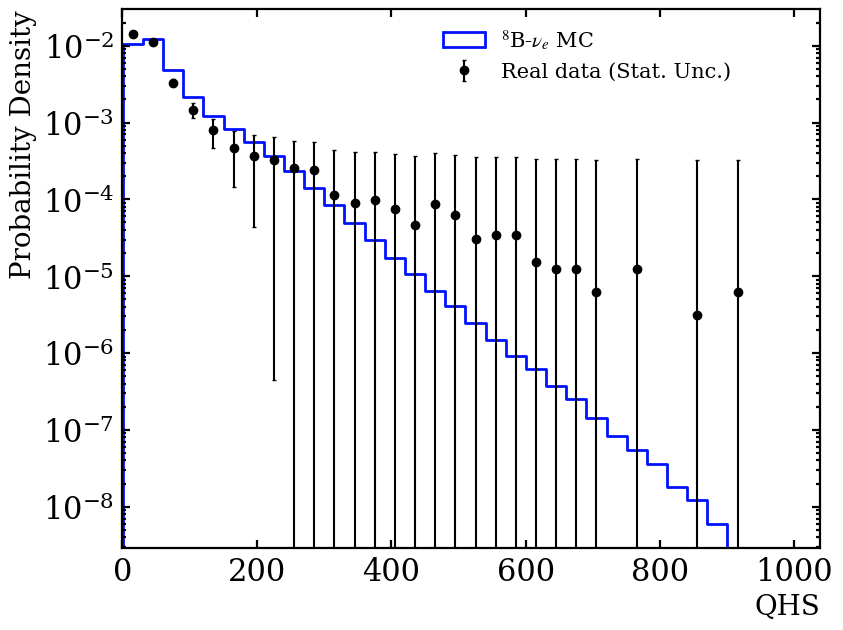

In [22]:
# Define axes: Construct subplots to conveniently represent the low contribution of the 208Tl spectrum
fig, ax = plt.subplots(1, 1,figsize=(9,7))

# Real data
ax.errorbar(qhs_bins_center_data, pdf_vals, yerr=pdf_errors, label = 'Real data (Stat. Unc.)', **errorbar_style)

# MC components
sn.histplot(x = hit_qhs_mc, bins = qhs_bins, stat = "density", element='step', 
            alpha=0, ax=ax, label=r'$^8$B-$\nu_e$ MC', color = '#0011ff', linewidth = linewidth)

ax.set_xlabel('QHS', fontsize = 20)
ax.set_ylabel('Probability Density', fontsize = 20)

ax.legend(loc = 'best', bbox_to_anchor=(0.9, 1), frameon=False, fontsize=15)

ax.set_yscale('log')

ax.set_xlim(0, max(hit_qhs_mc))
ax.set_ylim(0,)

plt.show()

### NOTES

QHL Distribution is out of expectations. Why does it Happens? Do I observe this in MC?
Big disagreement between data and MC!